In [61]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

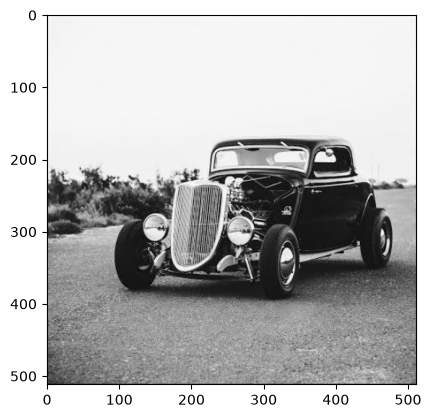

In [62]:
img = cv2.imread('lab6/img.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap = 'gray')

In [63]:
def haar_step(img):
    image = img.astype(np.float64)
    L = (image[:, 0::2] + image[:, 1::2]) / 2.0
    H = (image[:, 0::2] - image[:, 1::2]) / 2.0

    row_trans = np.hstack((L, H))

    LL_HL = (row_trans[0::2, :] + row_trans[1::2, :]) / 2.0
    LH_HH = (row_trans[0::2, :] - row_trans[1::2, :]) / 2.0

    return np.vstack((LL_HL, LH_HH))

In [64]:
def unpack_subbands(matrix):
    h, w = matrix.shape
    mid_h, mid_w = h // 2, w // 2

    LL = matrix[:mid_h, :mid_w]
    HL = matrix[:mid_h, mid_w:]
    LH = matrix[mid_h:, :mid_w]
    HH = matrix[mid_h:, mid_w:]

    return LL, HL, LH, HH

In [65]:
def do_step_with_print(image):
    next_step = haar_step(image.astype(np.float64))
    
    LL, HL, LH, HH = unpack_subbands(next_step)

    fig, axes = plt.subplots(1, 4, figsize=(15, 5))

    axes[0].imshow(LL, cmap='gray')
    axes[0].set_title("Average")

    axes[1].imshow(np.abs(HL), cmap='gray')
    axes[1].set_title("Horizontal Details")

    axes[2].imshow(np.abs(LH), cmap='gray')
    axes[2].set_title("Vertical Details")

    axes[3].imshow(np.abs(HH), cmap='gray')
    axes[3].set_title("Diagonal Details")

    return LL

In [66]:
# Step 1

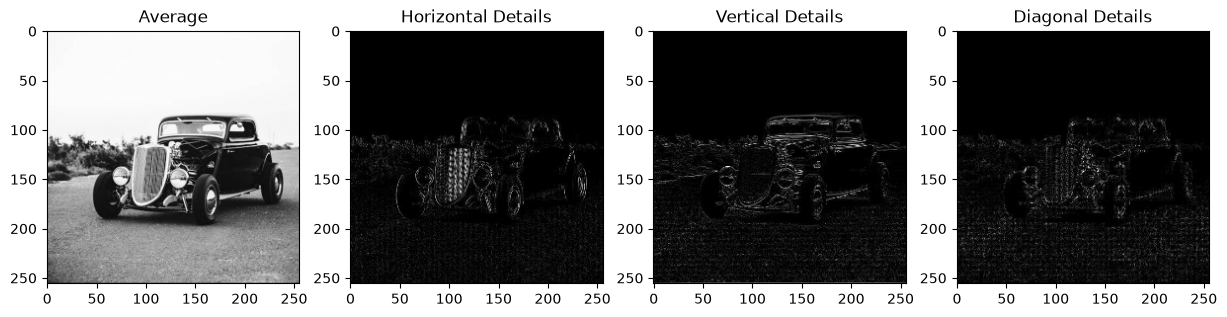

In [67]:
step1 = do_step_with_print(img)

In [68]:
# Step 2

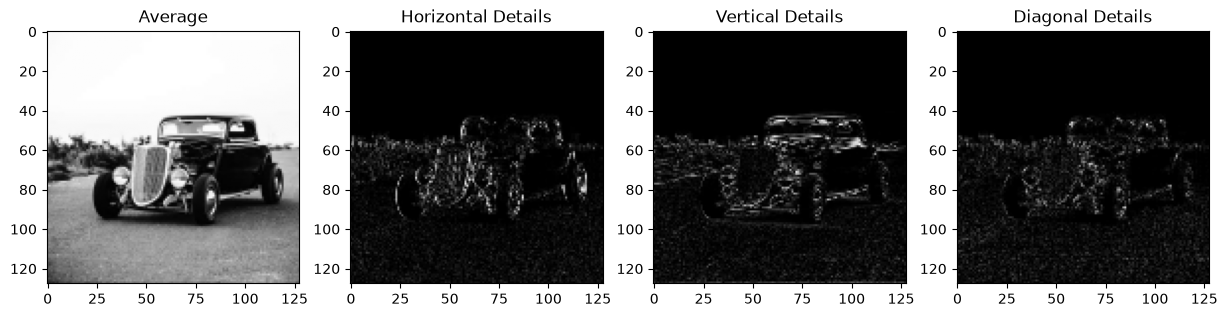

In [69]:
step2 = do_step_with_print(step1)

In [70]:
# Step 3

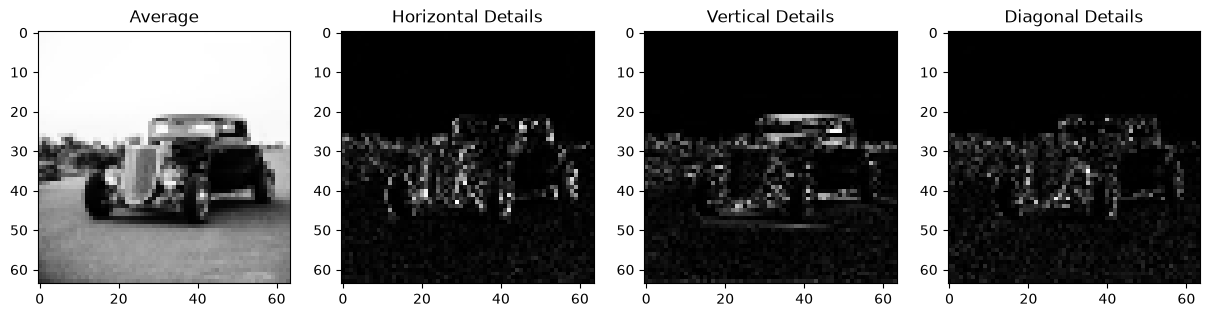

In [71]:
step3 = do_step_with_print(step2)